<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_4/dataset_pbl/praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 2**
# **Pengantar KMeans**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [ ]:
# Load dataset Sleep Health
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

# Pilih fitur numerik dan standarisasi
fitur = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']
scaler = StandardScaler()
X_all = scaler.fit_transform(df[fitur])

# Ambil 2 fitur utama (Sleep Duration & Quality of Sleep) untuk visualisasi 2D
X = X_all[:, [1, 2]]

# Encode target 'Sleep Disorder' (0: Insomnia, 1: None, 2: Sleep Apnea) untuk evaluasi akurasi nanti
le = LabelEncoder()
y_true = le.fit_transform(df['Sleep Disorder'].fillna('None'))
target_names = le.classes_

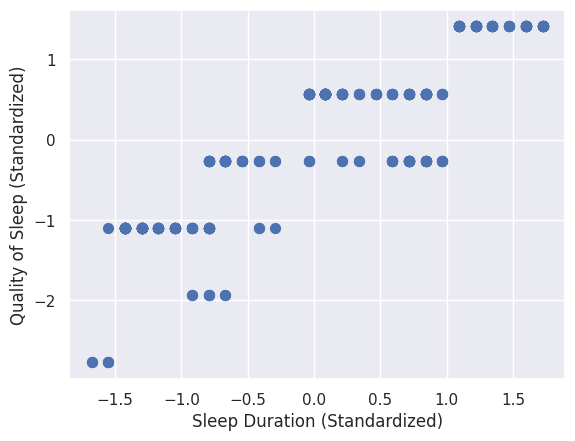

In [ ]:
# Plot data awal (Sleep Duration vs Quality of Sleep)
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.xlabel('Sleep Duration (Standardized)')
plt.ylabel('Quality of Sleep (Standardized)')
plt.show()

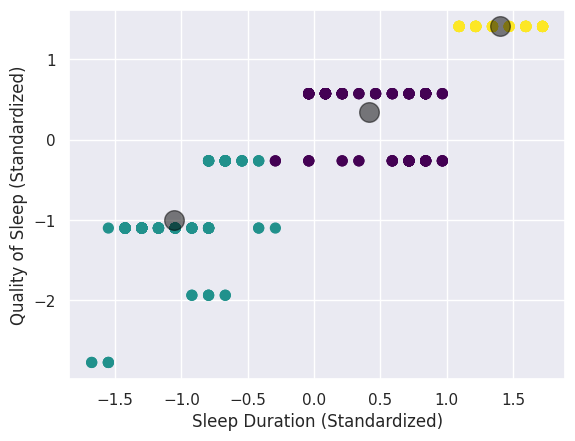

In [ ]:
from sklearn.cluster import KMeans

# Gunakan 3 klaster sesuai 3 kategori Sleep Disorder
kmeans = KMeans(n_clusters=3, random_state=0)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)
plt.xlabel('Sleep Duration (Standardized)')
plt.ylabel('Quality of Sleep (Standardized)')
plt.show()

## **Algoritma Expectation-Maximization**

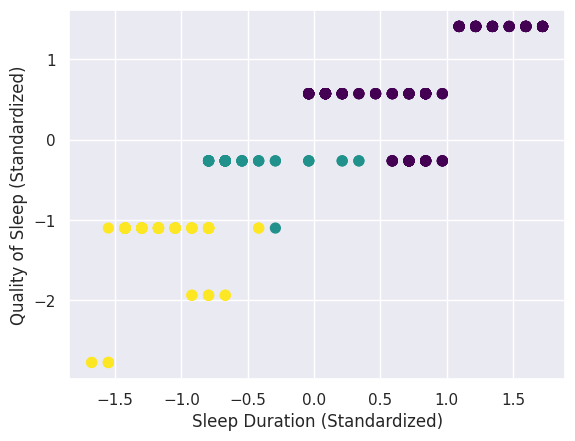

In [ ]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=42):
    # 1. Pilih titik awal dari data yang unik agar centroid tidak kembar
    rng = np.random.RandomState(rseed)
    X_unique = np.unique(X, axis=0)
    i = rng.permutation(X_unique.shape[0])[:n_clusters]
    centers = X_unique[i]

    while True:
        # 2a. Tentukan label berdasarkan centroid terdekat
        labels = pairwise_distances_argmin(X, centers)

        # 2b. Perbarui centroid dari rata-rata anggota klaster (abaikan jika kosong)
        new_centers = np.array([
            X[labels == i].mean(0) if np.any(labels == i) else centers[i]
            for i in range(n_clusters)
        ])

        # 2c. Cek konvergensi
        if np.all(centers == new_centers):
            break
        centers = new_centers

    return centers, labels

centers, labels = find_clusters(X, 3)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.xlabel('Sleep Duration (Standardized)')
plt.ylabel('Quality of Sleep (Standardized)')
plt.show()

## **Perubahan Random**

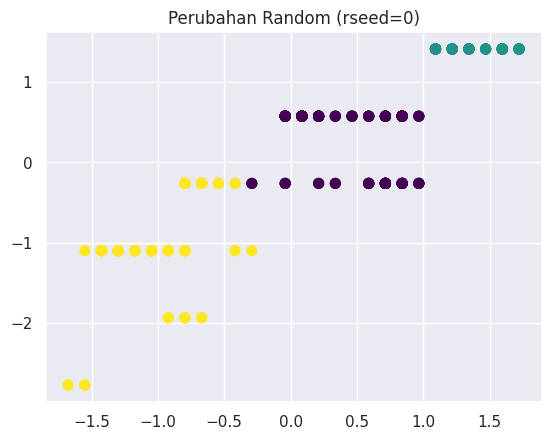

In [ ]:
# Perubahan seed acak (rseed=0)
centers, labels = find_clusters(X, 3, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.title('Perubahan Random (rseed=0)')
plt.show()

##**Optimalisasi Jumlah Klaster**

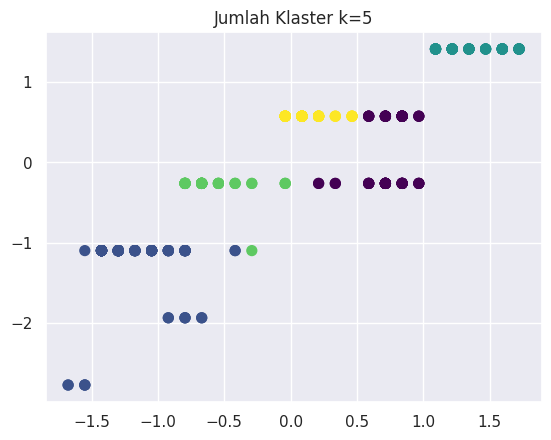

In [ ]:
# Mencoba jumlah klaster berlebih (misal k=5)
labels = KMeans(5, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.title('Jumlah Klaster k=5')
plt.show()

## **Batas Klaster yang Tidak selalu linier**

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


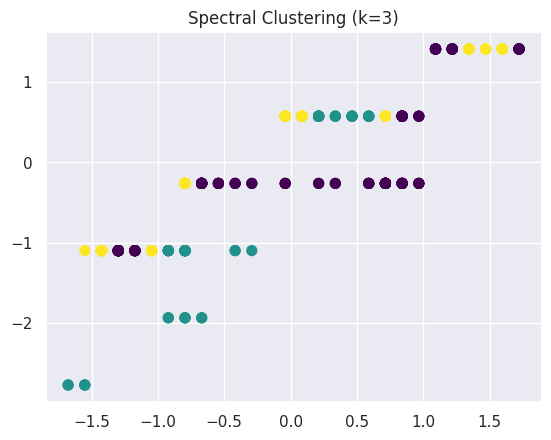

In [ ]:
from sklearn.cluster import SpectralClustering

# Membandingkan pengelompokan SpectralClustering pada data Sleep Health
model = SpectralClustering(n_clusters=3, affinity='nearest_neighbors',
                           assign_labels='kmeans', random_state=0)
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.title('Spectral Clustering (k=3)')
plt.show()

# **Contoh Kasus 1: Karakter Angka**

In [ ]:
# Terapkan K-Means pada seluruh 7 fitur numerik (X_all)
kmeans = KMeans(n_clusters=3, random_state=0)
clusters = kmeans.fit_predict(X_all)

In [ ]:
# Cocokkan label mayoritas tiap klaster dengan label asli Sleep Disorder
from scipy.stats import mode
from sklearn.metrics import accuracy_score, confusion_matrix

Akurasi K-Means (7 Fitur): 0.660427807486631


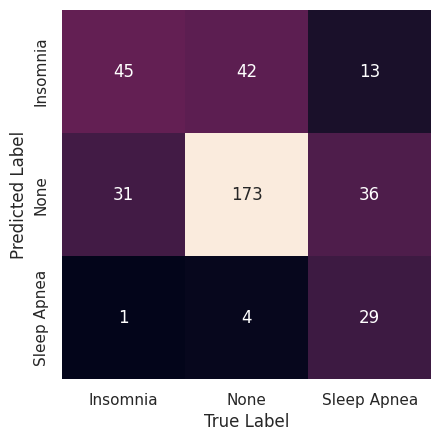

In [ ]:
labels = np.zeros_like(clusters)
for i in range(3):
    mask = (clusters == i)
    labels[mask] = mode(y_true[mask])[0]

print("Akurasi K-Means (7 Fitur):", accuracy_score(y_true, labels))

# Plot Confusion Matrix
mat = confusion_matrix(y_true, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=target_names,
            yticklabels=target_names)
plt.xlabel('True Label')
plt.ylabel('Predicted Label')
plt.show()

In [ ]:
# Reduksi dimensi menggunakan t-SNE sebelum klasterisasi K-Means
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, init='random', random_state=0)
sleep_proj = tsne.fit_transform(X_all)

# Hitung klaster pada data hasil proyeksi t-SNE
kmeans = KMeans(n_clusters=3, random_state=0)
clusters = kmeans.fit_predict(sleep_proj)

# Permutasi label
labels = np.zeros_like(clusters)
for i in range(3):
    mask = (clusters == i)
    labels[mask] = mode(y_true[mask])[0]

print("Akurasi K-Means + t-SNE:", accuracy_score(y_true, labels))

Akurasi K-Means + t-SNE: 0.5882352941176471
